# Scaling Laws Analysis

Analyze results from `scaling_laws.sh` to find the optimal param:data ratio for nanochat.

In [12]:
%matplotlib inline
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load results
tag = "armt_aug26"
base_dir = os.environ.get('NANOCHAT_BASE_DIR', os.path.expanduser('/home/jovyan/gkuzmin/nanoarmt/nano_data'))
results_path = os.path.join(base_dir, f'scaling_laws_results_{tag}', 'results.csv')

df = pd.read_csv(results_path)
flops_budgets = sorted(df['flops_budget'].unique())
print(f"Loaded {len(df)} runs across {len(flops_budgets)} FLOPs budgets")
print(f"Columns: {list(df.columns)}")
df

Loaded 19 runs across 4 FLOPs budgets
Columns: ['flops_budget', 'depth', 'model_dim', 'params_wte', 'params_value_embeds', 'params_lm_head', 'params_transformer', 'params_scalars', 'params_total', 'num_iterations', 'tokens_trained', 'val_bpb', 'core_score', 'train_time_sec']


,flops_budget,depth,model_dim,params_wte,params_value_embeds,params_lm_head,params_transformer,params_scalars,params_total,num_iterations,tokens_trained,val_bpb,core_score,train_time_sec
0,1.000000e+18,14,896,29360128,205520896,29360128,134873676,54,412001154,1582,829423616,0.885080,0.1272,14120
1,1.000000e+18,16,1024,33554432,268435456,33554432,201327360,58,555795258,1123,588775424,0.901683,0.1264,16033
2,1.000000e+18,20,1280,41943040,419430400,41943040,393217200,66,932645106,307,321912832,0.987315,0.0925,16313
3,2.150000e+18,20,1280,41943040,419430400,41943040,393217200,66,932645106,661,693108736,0.916634,0.1179,21957
4,1.000000e+18,18,1152,37748736,339738624,37748736,286655436,62,728491274,408,427819008,0.951591,0.0975,15548
5,2.150000e+18,12,768,25165824,150994944,25165824,84935088,50,294553058,5067,2656567296,0.844687,0.1418,24467
6,4.640000e+18,10,640,20971520,104857600,20971520,49152300,46,200895066,16858,8838447104,0.863375,0.1429,48098
7,2.150000e+18,18,1152,37748736,339738624,37748736,286655436,62,728491274,876,918552576,0.869407,0.1385,21995
8,1.000000e+18,10,640,20971520,104857600,20971520,49152300,46,200895066,3633,1904738304,0.878231,0.1328,12214
9,1.000000e+18,12,768,25165824,150994944,25165824,84935088,50,294553058,2357,1235746816,0.891597,0.1187,12901


In [13]:
# =============================================================================
# FILTERING: Remove incomplete or problematic runs
# =============================================================================

print(f"Before filtering: {len(df)} runs")

# Filter out runs with missing/invalid val_bpb (incomplete runs)
df = df[df['val_bpb'].notna() & (df['val_bpb'] > 0)]

# Optional: exclude specific flops budgets that aren't done yet
# exclude_flops = [1e19]  # <-- adjust as runs complete
# df = df[~df['flops_budget'].isin(exclude_flops)]

# Optional: exclude specific depths
# exclude_depths = [18, 20]
# df = df[~df['depth'].isin(exclude_depths)]

print(f"After filtering: {len(df)} runs")
print(f"FLOPs budgets: {sorted(df['flops_budget'].unique())}")
print(f"Depths: {sorted(df['depth'].unique())}")

# Update flops_budgets list after filtering
flops_budgets = sorted(df['flops_budget'].unique())
# for now, remove flops == 1e19 as unfinished
flops_budgets = sorted(df['flops_budget'].unique())[:-1]

Before filtering: 19 runs
After filtering: 19 runs
FLOPs budgets: [1e+18, 2.15e+18, 4.64e+18, 1e+19]
Depths: [10, 12, 14, 16, 18, 20]


## Effective Parameter Count

Different scaling law papers use different conventions for counting parameters:
- **Kaplan et al.** excluded embedding parameters (claimed cleaner laws)
- **Chinchilla** included all parameters (and noted Kaplan had a bug)

Our CSV now has granular counts:
- `params_wte` - token embedding (lookup table)
- `params_value_embeds` - value embeddings (lookup table)
- `params_lm_head` - unembedding projection (matmul)
- `params_transformer` - attention + MLP matrices (matmuls)
- `params_scalars` - resid/x0/bigram lambdas (tiny)

**Experiment below** with different combinations to see which gives the cleanest scaling laws.

In [14]:
# =============================================================================
# EXPERIMENT HERE: Define which parameters to count for scaling laws
# =============================================================================

def compute_effective_params(row):
    """
    Compute the 'effective' parameter count for scaling law analysis.

    Modify this function to experiment with different conventions:
    - Chinchilla-style: include everything
    - Kaplan-style: exclude embeddings
    - Matmul-only: just transformer + lm_head (the actual compute)
    - etc.
    """
    # Option 1: Chinchilla-style (all params)
    # return row['params_total']

    # Option 2: Kaplan-style (exclude embeddings)
    return row['params_transformer'] + row['params_lm_head']

    # Option 3: Transformer-only (exclude all embeddings AND lm_head)
    # return row['params_transformer']


# Compute derived columns
df = df.copy()  # avoid SettingWithCopyWarning from earlier filter
df['effective_params'] = df.apply(compute_effective_params, axis=1)
df['param_data_ratio'] = df['tokens_trained'] / df['effective_params']

# Show parameter breakdown for first few rows
print("Parameter breakdown (first row per flops budget):")
param_cols = ['depth', 'params_wte', 'params_value_embeds',
              'params_lm_head', 'params_transformer', 'params_scalars', 'params_total', 'effective_params']
df.groupby('flops_budget').first()[param_cols]

Parameter breakdown (first row per flops budget):


,depth,params_wte,params_value_embeds,params_lm_head,params_transformer,params_scalars,params_total,effective_params
flops_budget,,,,,,,,
1.000000e+18,14,29360128,205520896,29360128,134873676,54,412001154,164233804.0
2.150000e+18,20,41943040,419430400,41943040,393217200,66,932645106,435160240.0
4.640000e+18,10,20971520,104857600,20971520,49152300,46,200895066,70123820.0
1.000000e+19,10,20971520,104857600,20971520,49152300,46,200895066,70123820.0


## IsoFLOP Curves (à la Chinchilla)

For each compute budget, plot loss vs model size. Looking for the U-shape valley that reveals the optimal model size for each FLOPs budget.

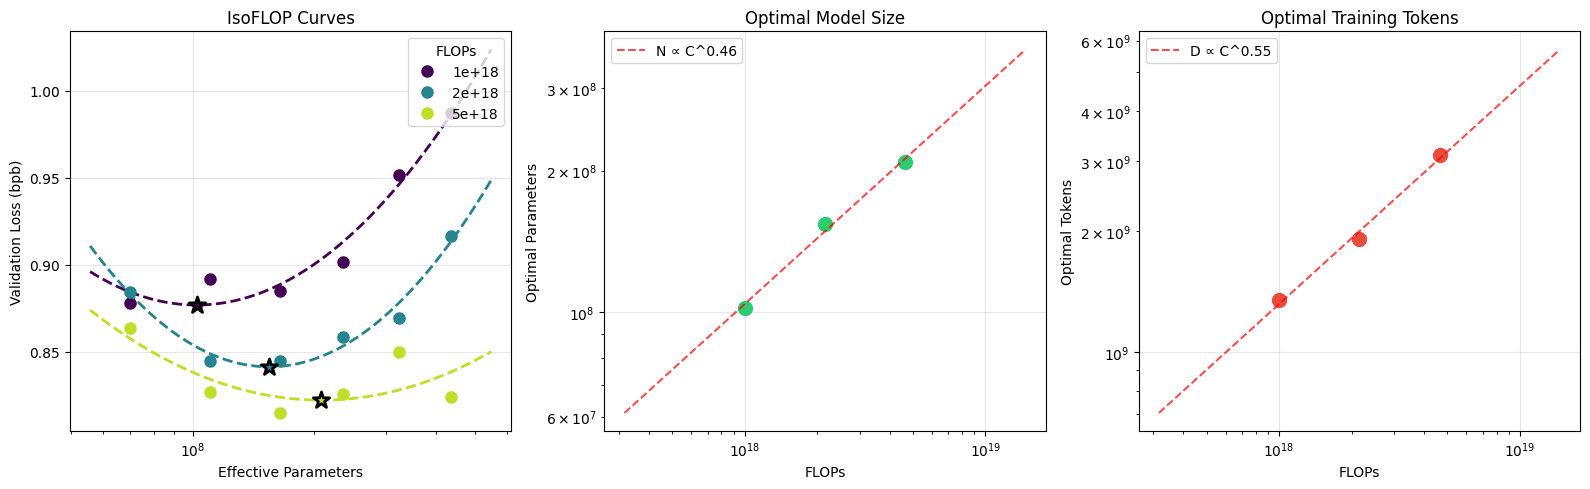


Optimal configurations (from quadratic fits):
FLOPs        Eff Params      Tokens          Ratio      Val BPB   
-----------------------------------------------------------------
1e+18        102,195,925     1,346,231,658   13.9       0.8769    
2e+18        154,376,333     1,918,302,915   12.9       0.8414    
5e+18        208,214,450     3,107,686,557   15.6       0.8222    


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

# Plot 1: IsoFLOP curves - Val BPB vs Parameters (the Chinchilla plot!)
ax = axes[0]
colors = plt.cm.viridis(np.linspace(0, 0.9, len(flops_budgets)))
optimal_by_bpb = []

for flops, color in zip(flops_budgets, colors):
    subset = df[df['flops_budget'] == flops].sort_values('effective_params')
    ax.plot(subset['effective_params'], subset['val_bpb'], 'o', color=color, label=f'{flops:.0e}', markersize=8)

    # Fit quadratic in log-space: val_bpb = a*(log N)^2 + b*(log N) + c
    log_params = np.log10(subset['effective_params'])
    coeffs = np.polyfit(log_params, subset['val_bpb'], 2)
    a, b, c = coeffs

    # Plot fitted curve (dashed)
    log_fit_x = np.linspace(log_params.min() - 0.1, log_params.max() + 0.1, 100)
    fit_y = a * log_fit_x**2 + b * log_fit_x + c
    ax.plot(10**log_fit_x, fit_y, '--', color=color, linewidth=2)

    # Find minimum of quadratic: d/dx(ax^2 + bx + c) = 0 => x = -b/(2a)
    if a > 0:  # parabola opens upward (has a minimum)
        log_opt = -b / (2 * a)
        opt_params = 10**log_opt
        opt_bpb = a * log_opt**2 + b * log_opt + c
        # Mark the fitted optimal
        ax.scatter([opt_params], [opt_bpb], s=150, color=color,
                   zorder=5, edgecolors='black', linewidths=2, marker='*')
        # Interpolate tokens and ratio from actual data (don't use C≈6ND approximation)
        opt_tokens = np.interp(np.log10(opt_params), log_params, subset['tokens_trained'])
        opt_ratio = np.interp(np.log10(opt_params), log_params, subset['param_data_ratio'])
        optimal_by_bpb.append({'flops': flops, 'params': opt_params, 'tokens': opt_tokens, 'ratio': opt_ratio, 'bpb': opt_bpb})
    else:
        # Fallback to raw minimum if quadratic doesn't have minimum
        best_idx = subset['val_bpb'].idxmin()
        best = subset.loc[best_idx]
        ax.scatter([best['effective_params']], [best['val_bpb']], s=150, color=color,
                   zorder=5, edgecolors='black', linewidths=2)
        optimal_by_bpb.append({'flops': flops, 'params': best['effective_params'],
                              'tokens': best['tokens_trained'], 'ratio': best['param_data_ratio'], 'bpb': best['val_bpb']})

ax.set_xscale('log')
ax.set_xlabel('Effective Parameters')
ax.set_ylabel('Validation Loss (bpb)')
ax.set_title('IsoFLOP Curves')
ax.legend(title='FLOPs', loc='upper right')
ax.grid(True, alpha=0.3)

opt_df = pd.DataFrame(optimal_by_bpb)

# Plot 2: Optimal model size vs compute (power law)
ax = axes[1]
ax.loglog(opt_df['flops'], opt_df['params'], 'o', markersize=10, color='#2ecc71')
ax.set_xlabel('FLOPs')
ax.set_ylabel('Optimal Parameters')
ax.set_title('Optimal Model Size')
ax.grid(True, alpha=0.3)

# Fit and show power law
if len(opt_df) >= 2:
    log_f = np.log10(opt_df['flops'])
    log_p = np.log10(opt_df['params'])
    slope, intercept = np.polyfit(log_f, log_p, 1)
    fit_f = np.logspace(log_f.min() - 0.5, log_f.max() + 0.5, 100)
    fit_p = 10**(intercept + slope * np.log10(fit_f))
    ax.plot(fit_f, fit_p, 'r--', alpha=0.7, label=f'N ∝ C^{slope:.2f}')
    ax.legend()

# Plot 3: Optimal tokens vs compute (power law)
ax = axes[2]
ax.loglog(opt_df['flops'], opt_df['tokens'], 'o', markersize=10, color='#e74c3c')
ax.set_xlabel('FLOPs')
ax.set_ylabel('Optimal Tokens')
ax.set_title('Optimal Training Tokens')
ax.grid(True, alpha=0.3)

# Fit and show power law
if len(opt_df) >= 2:
    log_f = np.log10(opt_df['flops'])
    log_t = np.log10(opt_df['tokens'])
    slope, intercept = np.polyfit(log_f, log_t, 1)
    fit_f = np.logspace(log_f.min() - 0.5, log_f.max() + 0.5, 100)
    fit_t = 10**(intercept + slope * np.log10(fit_f))
    ax.plot(fit_f, fit_t, 'r--', alpha=0.7, label=f'D ∝ C^{slope:.2f}')
    ax.legend()

plt.tight_layout()
plt.show()

# Print the optimal points (from quadratic fits)
print("\nOptimal configurations (from quadratic fits):")
print(f"{'FLOPs':<12} {'Eff Params':<15} {'Tokens':<15} {'Ratio':<10} {'Val BPB':<10}")
print("-" * 65)
for _, row in opt_df.iterrows():
    print(f"{row['flops']:<12.0e} {int(row['params']):<15,} {int(row['tokens']):<15,} {row['ratio']:<10.1f} {row['bpb']:<10.4f}")

In [16]:
# =============================================================================
# Optimal Ratio Summary (from power law fits)
# =============================================================================

# From the power law fits: N ∝ C^a and D ∝ C^b
# The ratio D/N ∝ C^(b-a). If a ≈ b, ratio is roughly constant.

if len(opt_df) >= 2:
    log_f = np.log10(opt_df['flops'])
    log_p = np.log10(opt_df['params'])
    log_t = np.log10(opt_df['tokens'])

    # Fit power laws
    slope_n, intercept_n = np.polyfit(log_f, log_p, 1)
    slope_d, intercept_d = np.polyfit(log_f, log_t, 1)

    # The ratio D/N at a reference compute (geometric mean of our budgets)
    ref_flops = np.sqrt(opt_df['flops'].min() * opt_df['flops'].max())
    log_ref = np.log10(ref_flops)

    # Predicted optimal N and D at reference compute
    pred_log_n = intercept_n + slope_n * log_ref
    pred_log_d = intercept_d + slope_d * log_ref
    optimal_ratio = 10**(pred_log_d - pred_log_n)

    # Also compute from the fitted optimals directly (mean and std)
    mean_ratio = opt_df['ratio'].mean()
    std_ratio = opt_df['ratio'].std()

    print("=" * 60)
    print("OPTIMAL RATIO SUMMARY")
    print("=" * 60)
    print(f"\nPower law exponents:")
    print(f"  N ∝ C^{slope_n:.3f}")
    print(f"  D ∝ C^{slope_d:.3f}")
    print(f"  Ratio exponent (b-a): {slope_d - slope_n:.3f}  (should be ~0 if ratio is constant)")
    print(f"\nOptimal ratio (tokens per effective param):")
    print(f"  From power law at C={ref_flops:.1e}: {optimal_ratio:.1f}")
    print(f"  Mean across budgets: {mean_ratio:.1f} ± {std_ratio:.1f}")
    print(f"  Chinchilla reference: 20")
    print(f"\nPer-budget ratios: {[f'{r:.1f}' for r in opt_df['ratio'].values]}")
else:
    print("Need at least 2 flops budgets to compute power law fits")

OPTIMAL RATIO SUMMARY

Power law exponents:
  N ∝ C^0.464
  D ∝ C^0.545
  Ratio exponent (b-a): 0.082  (should be ~0 if ratio is constant)

Optimal ratio (tokens per effective param):
  From power law at C=2.2e+18: 13.5
  Mean across budgets: 14.1 ± 1.4
  Chinchilla reference: 20

Per-budget ratios: ['13.9', '12.9', '15.6']


## Val BPB vs Depth and Ratio

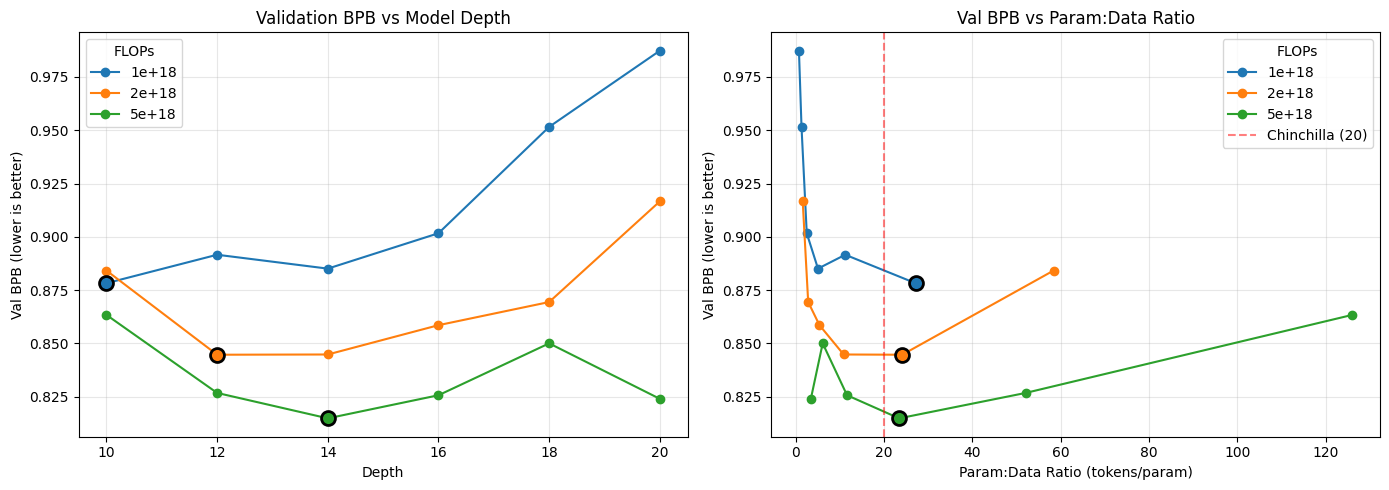

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Plot 1: Val BPB vs Depth
ax = axes[0]
for flops in flops_budgets:
    subset = df[df['flops_budget'] == flops].sort_values('depth')
    ax.plot(subset['depth'], subset['val_bpb'], 'o-', label=f'{flops:.0e}')
    # Mark the best (lowest)
    best_idx = subset['val_bpb'].idxmin()
    best = subset.loc[best_idx]
    ax.scatter([best['depth']], [best['val_bpb']], s=100, zorder=5, edgecolors='black', linewidths=2)

ax.set_xlabel('Depth')
ax.set_ylabel('Val BPB (lower is better)')
ax.set_title('Validation BPB vs Model Depth')
ax.legend(title='FLOPs')
ax.grid(True, alpha=0.3)

# Plot 2: Val BPB vs Param:Data Ratio
ax = axes[1]
for flops in flops_budgets:
    subset = df[df['flops_budget'] == flops].sort_values('param_data_ratio')
    ax.plot(subset['param_data_ratio'], subset['val_bpb'], 'o-', label=f'{flops:.0e}')
    best_idx = subset['val_bpb'].idxmin()
    best = subset.loc[best_idx]
    ax.scatter([best['param_data_ratio']], [best['val_bpb']], s=100, zorder=5, edgecolors='black', linewidths=2)

ax.axvline(x=20, color='red', linestyle='--', alpha=0.5, label='Chinchilla (20)')
ax.set_xlabel('Param:Data Ratio (tokens/param)')
ax.set_ylabel('Val BPB (lower is better)')
ax.set_title('Val BPB vs Param:Data Ratio')
ax.legend(title='FLOPs')
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()